# Gabriele's Notebook

In this notebook i test several models

In [1]:
import pandas as pd
import numpy as np

# Plots
import matplotlib.pyplot as plt
import seaborn as sns
from plotly import graph_objects as go

# Utils
from tqdm.notebook import tqdm
from tabulate import tabulate

# Sklearn
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import confusion_matrix, roc_auc_score, classification_report
import torch

# Custom modules
import Models_class as Models
import Dataset
import utils


# Set SEED
SEED = 42
np.random.seed(SEED)
torch.manual_seed(SEED)

# Set device
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Device: {device}")

Device: cuda


## Data loading

We first load the dataframe from the parquet file.

In [2]:
df = pd.read_parquet('../Data/FI-2010-Cleaned/NoAuction/Zscore/WRT1V.parquet')
df = df.head(20000)
df.drop(columns=['Label_10', 'Label_30', 'Label_50', 'Label_100', 'Day'], inplace=True)

target_cols = ['Label_20']
# Set target cols to dtype int
df[target_cols] = df[target_cols].astype(int)

df.head()

,P_Ask_0,V_Ask_0,P_Bid_0,V_Bid_0,P_Ask_1,V_Ask_1,P_Bid_1,V_Bid_1,P_Ask_2,V_Ask_2,...,V_Bid_7,P_Ask_8,V_Ask_8,P_Bid_8,V_Bid_8,P_Ask_9,V_Ask_9,P_Bid_9,V_Bid_9,Label_20
0,1.242406,-0.611621,1.240199,-0.446819,1.241779,-0.663252,1.240732,-0.512393,1.241182,-0.770717,...,-0.349285,1.238846,-0.418570,1.243297,-0.499588,1.236425,-0.444236,1.243820,-0.278126,1
1,1.241385,-0.678429,1.240199,-0.555044,1.240758,-0.663252,1.240732,-0.608105,1.240162,-0.770717,...,-0.480323,1.234773,-0.415537,1.244322,-0.339924,1.233373,-0.228680,1.245871,-0.448846,1
2,1.241385,-0.678429,1.240199,-0.465970,1.240758,-0.663252,1.240732,-0.608105,1.240162,-0.770717,...,-0.480323,1.234773,-0.415537,1.244322,-0.339924,1.233373,-0.228680,1.245871,-0.448846,1
3,1.241385,-0.678429,1.240199,-0.540792,1.240758,-0.663252,1.240732,-0.512393,1.240162,-0.770717,...,-0.480323,1.234773,-0.415537,1.244322,-0.339924,1.233373,-0.228680,1.245871,-0.448846,2
4,1.241385,-0.678429,1.240199,-0.540792,1.240758,-0.663252,1.240732,-0.512393,1.240162,-0.770717,...,-0.480323,1.234773,-0.415537,1.244322,-0.339924,1.233373,-0.228680,1.245871,-0.448846,0


Compute log-return from price variables

In [3]:
logreturn = lambda x: np.log(x) - np.log(x.shift(1))

price_cols = [col for col in df.columns if 'P_' in col]
df[price_cols] = df[price_cols].apply(logreturn, axis=0)
df.dropna(inplace=True)

In [4]:
#from statsmodels.tsa.stattools import adfuller

#result = adfuller(df['P_Ask_1'].values)

#print('ADF Statistic:', result[0])
#print('p-value:', result[1])
#print('Critical Values:', result[4])

In [5]:
# Split the dataframe into train and test
df_train, df_val, df_test = utils.DataTools.train_val_test_split(df)

# Split covariates and response variable(s)
X_train, y_train = utils.DataTools.split_x_y(df_train, target_cols)
X_val, y_val     = utils.DataTools.split_x_y(df_val, target_cols)
X_test, y_test   = utils.DataTools.split_x_y(df_test, target_cols)

# Standardize the covariates
scaler_X = StandardScaler()
X_train = scaler_X.fit_transform(X_train)
X_val = scaler_X.transform(X_val)
X_test = scaler_X.transform(X_test)

# Build tensors 
X_train, X_val, X_test = utils.DataTools.numpy_to_tensor( X_train, X_val, X_test, device=device, dtype=torch.float32 )
y_train, y_val, y_test = utils.DataTools.numpy_to_tensor( y_train, y_val, y_test, device=device, dtype=torch.long )

# Build TimeSeriesDataset
SEQ_LEN_X = 50
SEQ_LEN_Y = 1
OFFSET = 0
dataset_train = Dataset.TimeSeriesDataset(
    X         = X_train,
    y         = y_train,
    seq_len_x = SEQ_LEN_X,
    seq_len_y = SEQ_LEN_Y,
    offset    = OFFSET,
    channels  = False,
    task      = Dataset.TimeSeriesDataset.Task.CLASSIFICATION
)
dataset_val = Dataset.TimeSeriesDataset(
    X         = X_val,
    y         = y_val,
    seq_len_x = SEQ_LEN_X,
    seq_len_y = SEQ_LEN_Y,
    offset    = OFFSET,
    channels  = False,
    task      = Dataset.TimeSeriesDataset.Task.CLASSIFICATION
)
dataset_test = Dataset.TimeSeriesDataset(
    X         = X_test,
    y         = y_test,
    seq_len_x = SEQ_LEN_X,
    seq_len_y = SEQ_LEN_Y,
    offset    = OFFSET,
    channels  = False,
    task      = Dataset.TimeSeriesDataset.Task.CLASSIFICATION
)

# Build TimeSeriesLoader
BATCH_SIZE = 32
dataloader_train = Dataset.TimeSeriesLoader(
    dataset = dataset_train,
    batch_size = BATCH_SIZE,
    shuffle = True
)
dataloader_val = Dataset.TimeSeriesLoader(
    dataset = dataset_val,
    batch_size = BATCH_SIZE,
    shuffle = False
)
dataloader_test = Dataset.TimeSeriesLoader(
    dataset = dataset_test,
    batch_size = 1024,
    shuffle = False
)

In [6]:
print(f'Train dataset: {len(dataset_train)} samples')
print(f'Test dataset: {len(dataset_test)} samples')

Train dataset: 13949 samples
Test dataset: 2951 samples


## Models

### Basic LSTM

In [7]:
dataloader_train.dataset.channels = False
dataloader_val.dataset.channels = False
dataloader_test.dataset.channels = False

The model has 81795 parameters


Training:   0%|          | 0/200 [00:00<?, ?it/s]

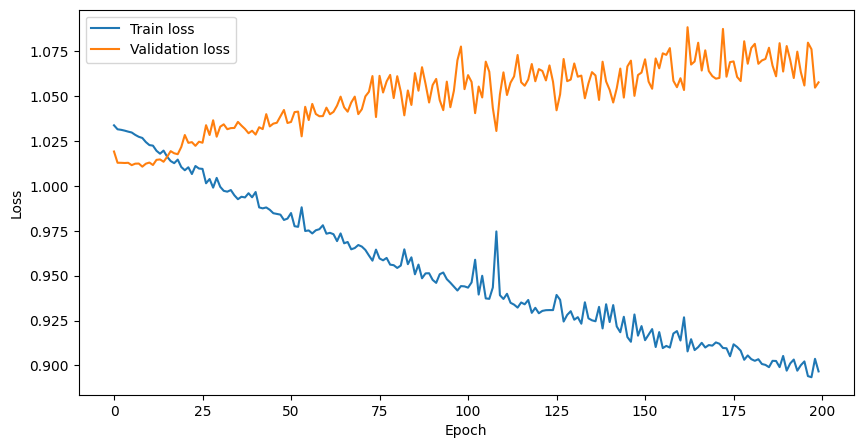

In [11]:
# Create the model
model_params = {
    'input_size': X_train.shape[1],
    'output_size': 3,
    'hidden_size': 64,
    'num_layers': 2,
    'dropout': 0.2
}
model = utils.ModelTools.build_model(Models.LSTM, model_params).to(device)

# Optimizer parameters
LEARNING_RATE = 3e-5
optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)
criterion = torch.nn.CrossEntropyLoss()

# Print the number of parameters
n_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f'The model has {n_params} parameters')

# Train the model
train_res = utils.train(
    train_loader = dataloader_train,
    val_loader = dataloader_val,
    model = model,
    optimizer = optimizer,
    criterion = criterion,
    device = device,
    n_epochs = 200,
)

# Plot loss evolution
plt.figure(figsize=(10, 5))
plt.plot(train_res['losses_train'], label='Train loss')
plt.plot(train_res['losses_val'], label='Validation loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.show()

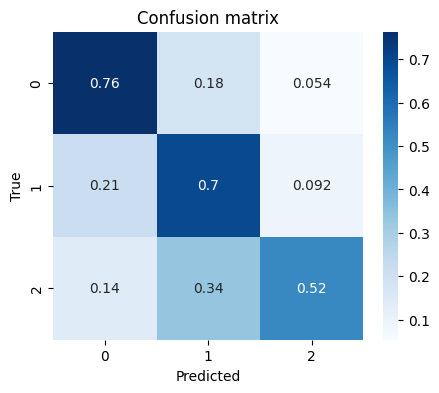

In [9]:
evaluation_res = utils.evaluate(
    model = model,
    loader = dataloader_test,
    criterion = criterion,
    device = device
)

true = np.concatenate(evaluation_res['true'], axis=0)
pred = np.concatenate(evaluation_res['pred'], axis=0)
pred = np.argmax(pred, axis=1)

# Confusion matrix
conf_matrix = confusion_matrix(true, pred.round(), normalize='true')
plt.figure(figsize=(5, 4))
sns.heatmap(conf_matrix, annot=True, cmap='Blues')
plt.xlabel('Predicted')
plt.ylabel('True')
plt.title('Confusion matrix')
plt.show()

In [10]:
print(classification_report(true, pred, zero_division=0))

y_pred = np.concatenate(evaluation_res['pred'], axis=0)
y_true = np.concatenate(evaluation_res['true'], axis=0)
roc_auc_score(y_true, y_pred, multi_class='ovo')
print(f'AUC: {roc_auc_score(y_true, y_pred, multi_class="ovo")}')

              precision    recall  f1-score   support

           0       0.62      0.76      0.68       836
           1       0.72      0.70      0.71      1417
           2       0.68      0.52      0.59       698

    accuracy                           0.67      2951
   macro avg       0.67      0.66      0.66      2951
weighted avg       0.68      0.67      0.67      2951

AUC: 0.7727668723765042


### Aragosta

In [8]:
dataloader_train.dataset.channels = True
dataloader_val.dataset.channels = True
dataloader_test.dataset.channels = True

The model has 216323 parameters


Training:   0%|          | 0/20 [00:00<?, ?it/s]

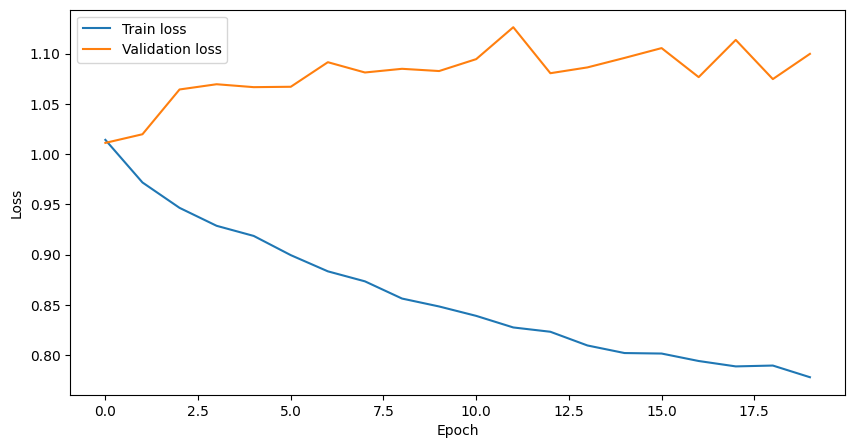

In [9]:
# Create the model
model_params = {
    'input_size': X_train.shape[1],
    'output_size': 3, # TODO !!!
    'hidden_size': 64,
    'lstm_size': 64,
    'lstm_layers': 2,
    'conv_channels': 64,
    'inception_channels': 64,
    'dropout_rate': 0.2
}
model = utils.ModelTools.build_model(Models.Aragosta, model_params).to(device)

# Optimizer parameters
LEARNING_RATE = 1e-4
optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)
criterion = torch.nn.CrossEntropyLoss()

# Print the number of parameters
n_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f'The model has {n_params} parameters')

# Train the model
train_res = utils.train(
    train_loader = dataloader_train,
    val_loader = dataloader_val,
    model = model,
    optimizer = optimizer,
    criterion = criterion,
    device = device,
    n_epochs = 20,
)

# Plot loss evolution
plt.figure(figsize=(10, 5))
plt.plot(train_res['losses_train'], label='Train loss')
plt.plot(train_res['losses_val'], label='Validation loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.show()

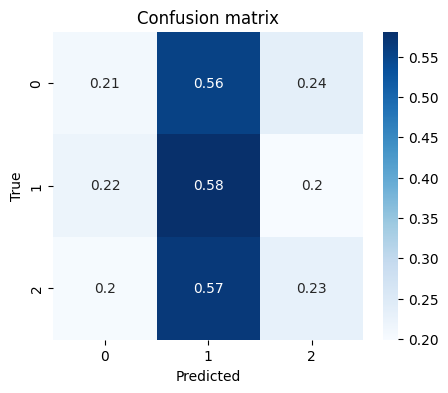

In [10]:
evaluation_res = utils.evaluate(
    model = model,
    loader = dataloader_test,
    criterion = criterion,
    device = device
)

true = np.concatenate(evaluation_res['true'], axis=0)
pred = np.concatenate(evaluation_res['pred'], axis=0)
pred = np.argmax(pred, axis=1)

# Confusion matrix
conf_matrix = confusion_matrix(true, pred.round(), normalize='true')
plt.figure(figsize=(5, 4))
sns.heatmap(conf_matrix, annot=True, cmap='Blues')
plt.xlabel('Predicted')
plt.ylabel('True')
plt.title('Confusion matrix')
plt.show()

In [11]:
print(classification_report(true, pred, zero_division=0))

y_pred = np.concatenate(evaluation_res['pred'], axis=0)
y_true = np.concatenate(evaluation_res['true'], axis=0)
roc_auc_score(y_true, y_pred, multi_class='ovo')
print(f'AUC: {roc_auc_score(y_true, y_pred, multi_class="ovo")}')

              precision    recall  f1-score   support

           0       0.28      0.21      0.24       836
           1       0.49      0.58      0.53      1417
           2       0.25      0.23      0.24       698

    accuracy                           0.39      2951
   macro avg       0.34      0.34      0.34      2951
weighted avg       0.37      0.39      0.38      2951

AUC: 0.5067430444367067
